<a href="https://colab.research.google.com/github/Pranayshukla0610/Data-Engineering-Projects/blob/main/Business_Statistics_%26_ANOVA_Mastery_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

NumPy handles numerical arrays, Pandas handles tables, Matplotlib/Seaborn create charts, SciPy provides statistical tests, and Statsmodels provides ANOVA models and tables.

In [1]:
!pip install statsmodels pingouin

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from pathlib import Path
import pingouin as pg

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [3]:
import warnings
warnings.filterwarnings('ignore')
np.random.seed(2026)
sns.set_theme(style='whitegrid')
print("Environment Ready")

Environment Ready


1. Statistical foundations: population, sample, parameter and statistic
- Population: the complete group we want to understand, such as all customers in a defined year.
- Sample: a subset selected from that population.
- Parameter: a numerical characteristic of the population, such as population mean μ.
- Statistic: a number calculated from a sample, such as sample mean x̄.
- Census: measuring every unit in the defined population. It avoids sampling error for that population, but not measurement error, missing data or processing mistakes.
- Sampling error: natural variation between a sample statistic and the population parameter because only part of the population was observed. This is different from selection bias.
Observational unit: the entity represented by one row. Here, one row represents one customer.

In [4]:
N = 6000
campaigns = np.random.choice(["Email","Social","Search","Referral"],N,
                             p=[.25,.30,.30,.15])

campaign_effect = pd.Series(campaigns).map(
    {"Email":0, "Social":250, "Search":450, "Referral":650}
).to_numpy()

raw = pd.DataFrame({
    "customer_id":np.arange(1, N+1),
    "campaign":campaigns,
    "age":np.random.randint(18, 71, N),
    "monthly_spend":np.random.normal(2500,650,N) + campaign_effect,
    "orders":np.random.poisson(4,N) + 1,
    "satisfaction":np.random.choice([1,2,3,4,5], N, p=[.04, .08, .18, .40, .30]),
    "tenure_months":np.random.gamma(2.5, 8, N)
})

raw.loc[[10, 220, 1100, 3500], "monthly_spend"] *= 3.5
data = raw.copy()
display(data.head())
print("Rows and columns:",data.shape)

,customer_id,campaign,age,monthly_spend,orders,satisfaction,tenure_months
0,1,Email,49,2136.944794,7,3,17.764855
1,2,Social,67,2787.026884,6,5,13.385018
2,3,Referral,47,1904.278406,3,5,17.069778
3,4,Email,42,1954.164090,6,3,15.634004
4,5,Social,27,3019.627306,6,5,7.753400


Rows and columns: (6000, 7)


Interpretation: For this exercise, the 6,000 generated rows form the available population. In real work, define the population precisely by dates, geography, customer status and inclusion rules. An undefined population makes conclusions ambiguous.
1A. Variable types and measurement scales
- Nominal: labels without natural order (campaign).
- Ordinal: ordered categories with unequal/unknown spacing (satisfaction rating).
- Discrete numeric: counts (orders).
- Continuous numeric: measurements (spend, tenure).
- An ID is a label, even if stored as an integer. Do not calculate its mean as if it measured customer behaviour.

In [5]:
display(data.dtypes.to_frame("dtype"))
display(data.isna().sum().to_frame("missing"))
print("Campaign counts:")
display(data["campaign"].value_counts())

,dtype
customer_id,int64
campaign,str
age,int64
monthly_spend,float64
orders,int64
satisfaction,int64
tenure_months,float64


,missing
customer_id,0
campaign,0
age,0
monthly_spend,0
orders,0
satisfaction,0
tenure_months,0


Campaign counts:


campaign
Search      1827
Social      1807
Email       1458
Referral     908
Name: count, dtype: int64

A statistical calculation can be precisely wrong if the data is poor. Audit missing values, duplicates, impossible values, units and definitions. Preserve the raw input and make a separate analysis copy.

In [6]:
print("Duplicate IDs:", data["customer_id"].duplicated().sum())
print("Missing values:")
display(data.isna().sum().to_frame("count"))
print("Negative spend:", (data["monthly_spend"] < 0).sum())
print("Age outside 18–100:", (~data["age"].between(18,100)).sum())

data = data.drop_duplicates("customer_id")
data = data.dropna(subset=["campaign", "monthly_spend"])
data = data[data["monthly_spend"] >= 0].copy()

assert data["customer_id"].is_unique
assert data["monthly_spend"].notna().all()
assert (data["monthly_spend"] >= 0).all()
print("Validated rows:", len(data))

Duplicate IDs: 0
Missing values:


,count
customer_id,0
campaign,0
age,0
monthly_spend,0
orders,0
satisfaction,0
tenure_months,0


Negative spend: 0
Age outside 18–100: 0
Validated rows: 6000


Interpretation: Cleaning rules must be explicit and justified. Do not remove a high spend value merely because it is unusual; it may be a genuine premium customer. Distinguish invalid records from valid extreme observations.

Descriptive statistics organize and summarize the observations actually collected. They describe center, spread, shape and frequency. They do not, by themselves, prove causes or generalize to a wider population.

They answer: How many records? What is typical? How much variation exists? Is the distribution skewed? Are there unusual values?

In [7]:
numeric_cols = ['age','monthly_spend', 'orders', 'satisfaction','tenure_months']
display(data[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,6000.0,44.179833,15.344317,18.000000,31.000000,44.000000,58.000000,70.000000
monthly_spend,6000.0,2815.744484,699.936115,501.576122,2352.754002,2806.686735,3265.885345,10312.632378
orders,6000.0,4.983333,2.004842,1.000000,4.000000,5.000000,6.000000,15.000000
satisfaction,6000.0,3.837833,1.069763,1.000000,3.000000,4.000000,5.000000,5.000000
tenure_months,6000.0,19.845584,12.759250,0.215892,10.546392,17.142475,26.291033,106.664814


How to interpret describe():
- count: non-missing observations.
- mean: arithmetic average.
- std: sample standard deviation in Pandas (ddof=1).
- min, max: observed extremes.
- 25%, 50%, 75%: quartiles.
  This table does not show every feature of a distribution; combine it with plots and context.

In [8]:
x = data['monthly_spend']
print("Mean:",x.mean())
print("Median:",x.median())
print("Mode:",x.mode().tolist()[:10])
print("Most common campaign:",data["campaign"].mode().tolist())

Mean: 2815.7444843012568
Median: 2806.686734920825
Mode: [501.57612214562823, 502.5826566136882, 550.9055130775484, 646.1392251196655, 710.3031524451828, 752.9276198462512, 757.8332544862301, 786.2750700116992, 851.5819150324228, 929.9209424957357]
Most common campaign: ['Search']


Interpretation: Mean greater than median can indicate that high values pull the average upward. This is a clue of possible right skew, not proof. Check a histogram and skewness. Median often better describes a typical customer in a skewed spending distribution.

In [9]:
a = pd.Series([10, 12, 13, 14, 15, 16])
b = pd.Series([10, 12, 13, 14, 160])

display(pd.DataFrame({"ordinary":[a.mean(),a.median()],
                      "with_extreme":[b.mean(),b.median()]},
                     index=["mean","median"]))

,ordinary,with_extreme
mean,13.333333,41.8
median,13.500000,13.0


Interpretation: The extreme value changes the mean much more than the median. Median is robust to an isolated extreme observation, but it does not describe every aspect of the distribution.

In [10]:
q1, median, q3 = x.quantile([0.25, 0.50, 0.75])
iqr = q3 - q1

print("Range:",x.max() - x.min())
print("Population Variance:",x.var(ddof=0))
print("Sample Variance:",x.var(ddof=1))
print("Population_SD:",x.std(ddof=0))
print("Sample_SD:",x.std(ddof=1))
print("Q1/Median/Q3:",q1, median, q3)
print("IQR:",iqr)
print("CV (%):",x.std(ddof=1)/x.mean()*100)

Range: 9811.056255844174
Population Variance: 489828.9136613238
Sample Variance: 489910.5654222275
Population_SD: 699.8777848034068
Sample_SD: 699.9361152435467
Q1/Median/Q3: 2352.754002438639 2806.686734920825 3265.885344680298
IQR: 913.1313422416592
CV (%): 24.857941448378256


Interpretation:
- Variance is in squared currency units, so SD is easier to communicate.
- Sample SD is generally slightly larger than population SD for the same non-constant data because it uses n−1.
- IQR focuses on the middle half and is less influenced by extremes.
- CV compares relative variability, not absolute variability.


5A. Calculate variance manually
Cell 26 of 96

5A. Calculate variance manually
The deviations from the mean are squared so positive and negative differences do not cancel, and large deviations receive greater weight.

#VARIANCE

In [11]:
values = np.array([4,6,6,8,11],dtype=float)
m = values.mean()
sq_dev = (values - m) ** 2
pop_var = sq_dev.sum() / len(values)
sam_var = sq_dev.sum() / (len(values) - 1)
print("Values:",values)
print("Mean:",m)
print("Standard Deviation:",sq_dev)
print("Sum Squared Deviations:",sq_dev.sum())
print("Population Variance:",pop_var)
print("Sample Variance:",sam_var)
print("Population SD:",np.sqrt(pop_var))
print("Sample SD:",np.sqrt(sam_var))

Values: [ 4.  6.  6.  8. 11.]
Mean: 7.0
Standard Deviation: [ 9.  1.  1.  1. 16.]
Sum Squared Deviations: 28.0
Population Variance: 5.6
Sample Variance: 7.0
Population SD: 2.3664319132398464
Sample SD: 2.6457513110645907


Interpretation: Sample variance uses n−1 (Bessel's correction) because estimating the mean from the sample uses one degree of freedom. This corrects the downward bias of the usual sample squared-deviation average when estimating population variance under standard random-sampling assumptions.

In [13]:
spread_demo = pd.DataFrame({
    "Group A":[48,49,50,51,52],
    "Group B":[20,35,50,65,80]
})

display(spread_demo.agg(["mean","median","std","var"]))

,Group A,Group B
mean,50.000000,50.000000
median,50.000000,50.000000
std,1.581139,23.717082
var,2.500000,562.500000


Interpretation: Both groups have the same mean and median, but Group B varies much more. Reporting only the mean would hide a meaningful difference in consistency.

In [16]:
percentiles = [5,10,25,50,75,90,95,99]
display(pd.DataFrame({
    "percentile":percentiles,
    "spend_value":[x.quantile(p/100, interpolation='linear') for p in percentiles]
}).round(2))

,percentile,spend_value
0,5,1684.11
1,10,1937.94
2,25,2352.75
3,50,2806.69
4,75,3265.89
5,90,3702.10
6,95,3947.10
7,99,4385.44


Interpretation: If the 90th percentile is ₹4,000, approximately 90% of customers spend at or below ₹4,000 and 10% above it. It does not mean the top 10% all spend the same amount.

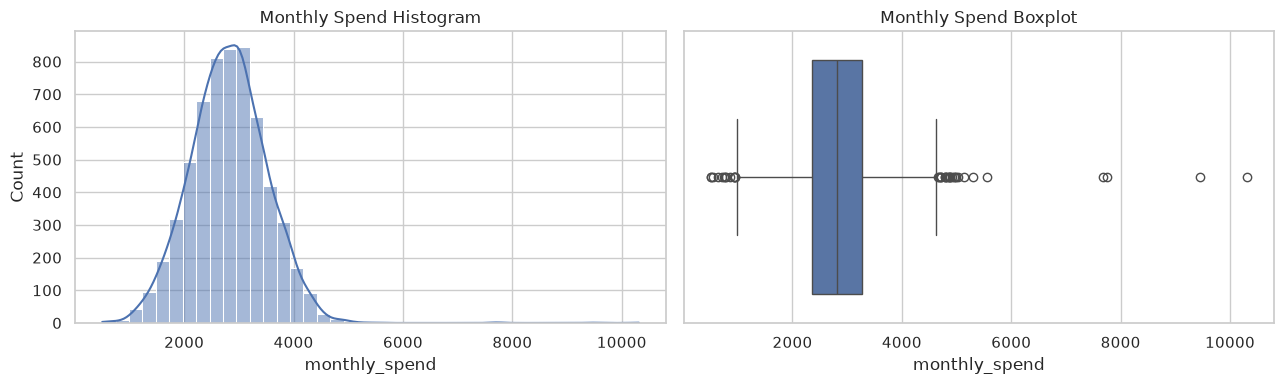

Skewness: 0.47525395590171843
Excess Krtosis: 4.0164173629107225


In [18]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
sns.histplot(x, bins=40, kde=True, ax=axes[0])
axes[0].set_title("Monthly Spend Histogram")
sns.boxplot(x=x, ax = axes[1])
axes[1].set_title("Monthly Spend Boxplot")
plt.tight_layout()
plt.show()
print("Skewness:",x.skew())
print("Excess Krtosis:",x.kurt())

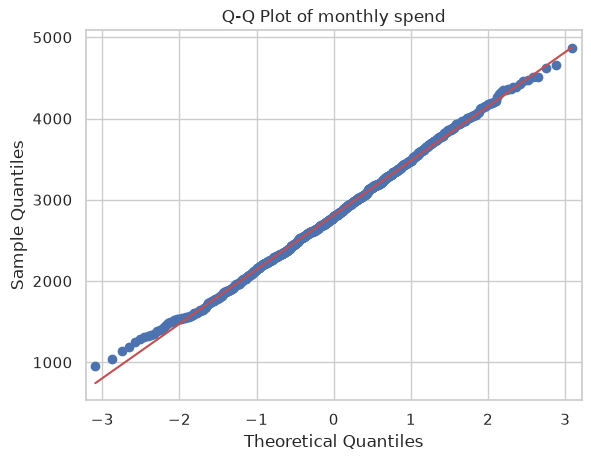

In [19]:
sm.qqplot(x.sample(min(1000,len(x)),random_state=42),line='s')
plt.title("Q-Q Plot of monthly spend")
plt.show()

Q-Q interpretation: Points roughly following the line are broadly consistent with normal quantiles. Curvature or tail departures suggest a different distribution. Large samples reveal even small departures, so consider practical relevance.

#Z-scores and outlier screening

In [20]:
z = (x-x.mean()/x.std(ddof=0))
q1,q3 = x.quantile([.25,.75])
spread = q3 - q1
lo,hi = q1 - 1.5 * spread, q3 + 1.5 * spread
print("Z-Score Flags:",(z.abs()>3).sum())
print("IQR Flags:",((x<lo)|(x>hi)).sum())
print("Lower / upper fences", lo, hi)

Z-Score Flags: 6000
IQR Flags: 38
Lower / upper fences 983.0569890761501 4635.582358042787


Interpretation: The two methods can flag different records because they use different definitions of center and spread. Investigate source records and business rules before correcting, retaining, transforming or excluding observations.

#Covariance and correlation

Covariance indicates whether two variables tend to vary together. Its magnitude depends on measurement units.

Pearson correlation standardizes covariance and measures linear association from −1 to +1.

Spearman correlation measures rank-based monotonic association and can capture monotonic but nonlinear patterns.

Neither proves causation. Confounding, selection effects, outliers and nonlinear relationships can mislead.

Covariance:


,monthly_spend,orders,age,tenure_months
monthly_spend,489910.57,-2.75,-36.23,-28.01
orders,-2.75,4.02,0.53,0.31
age,-36.23,0.53,235.45,-3.28
tenure_months,-28.01,0.31,-3.28,162.80


Pearson


,monthly_spend,orders,age,tenure_months
monthly_spend,1.000,-0.002,-0.003,-0.003
orders,-0.002,1.000,0.017,0.012
age,-0.003,0.017,1.000,-0.017
tenure_months,-0.003,0.012,-0.017,1.000


Spearman


,monthly_spend,orders,age,tenure_months
monthly_spend,1.000,-0.005,-0.002,-0.001
orders,-0.005,1.000,0.016,0.015
age,-0.002,0.016,1.000,-0.020
tenure_months,-0.001,0.015,-0.020,1.000


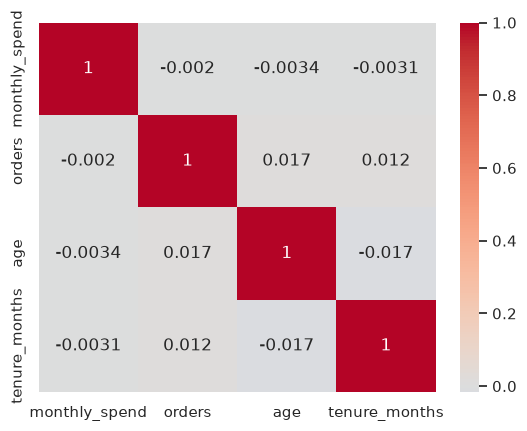

Orders vs Monthly Spend


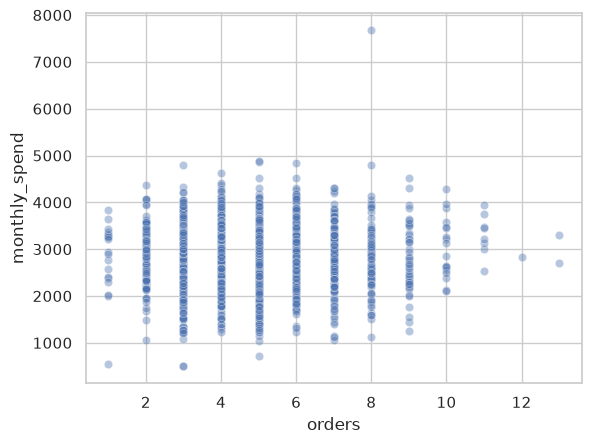

In [22]:
cols = data[['monthly_spend',"orders","age","tenure_months"]]

print("Covariance:");display(cols.cov().round(2))
print("Pearson");display(cols.corr(method='pearson').round(3))
print("Spearman");display(cols.corr(method='spearman').round(3))
sns.heatmap(cols.corr(),annot=True,cmap='coolwarm',center=0)
plt.show()
sns.scatterplot(data=data.sample(1500, random_state=4),
                x='orders',y='monthly_spend',alpha=.4)

print("Orders vs Monthly Spend")
plt.show()

Interpretation: Identify sign, strength and shape. Near-zero Pearson correlation means little linear association, not necessarily no relationship. A positive association between orders and spend does not prove that more orders cause more spending.

#Sampling distribution, standard error and confidence interval

A sampling distribution is the distribution of a statistic across repeated samples of the same size from the same population.

Standard error (SE) is the standard deviation of a statistic's sampling distribution. For a sample mean, estimated SE = sample SD / √n.

A 95% confidence procedure produces intervals that, over repeated random samples and under its assumptions, contain the fixed population parameter about 95% of the time. It does not mean there is a 95% probability that the fixed parameter lies in this already-calculated interval.

In [23]:
sample = x.sample(250,random_state=123)
n = len(sample)
mean = sample.mean()
sd = sample.std(ddof=1)
se = sd/np.sqrt(n)
tcrit = stats.t.ppf(.975,df=n-1)
margin = tcrit*se
print("Sample mean:",mean)
print("Sample SD:",sd)
print("Standard error:",se)
print("95% t confidence interval:",(mean-margin,mean+margin))

Sample mean: 2792.1841775953753
Sample SD: 716.7285601329514
Standard error: 45.32989428226163
95% t confidence interval: (np.float64(2702.9052796002566), np.float64(2881.463075590494))


#Hypothesis testing

Null hypothesis (H0): default claim, often no difference or no association.
Alternative hypothesis (H1): competing claim.
Significance level (α): preselected long-run Type I error threshold, commonly 0.05.
p-value: assuming H0 and model assumptions are true, probability of a test statistic at least as extreme as observed.

A p-value is not the probability H0 is true and not the probability that results happened “by chance”.
- p < α: reject H0 under the chosen rule.
- p ≥ α: fail to reject H0; this does not prove H0.
- Type I error: reject a true H0.
- Type II error: fail to reject a false H0.
- Statistical significance is not the same as practical importance.

#ANOVA: Analysis of Variance

ANOVA is a family of methods for comparing means across groups. One-way ANOVA tests whether the population means of a continuous outcome are equal across three or more independent groups defined by one categorical factor.

Business question: Is average monthly customer spending equal across Email, Social, Search and Referral campaigns?

Hypotheses:
- H0: μEmail = μSocial = μSearch = μReferral.
- H1: At least one population mean differs.
A significant omnibus ANOVA does not tell you which groups differ. Suitable post-hoc comparisons are needed.

#ANOVA intuition

ANOVA compares between-group variation with within-group variation. If group means are far apart relative to the spread inside groups, the F statistic tends to be large.

F = between-group variation / within-group variation

The interactive illustration below lets you change observations and see how the balance changes.

In [24]:
display(data.groupby('campaign')['monthly_spend'].agg(['count','mean','std']).round(2))
print("Grand mean:",data["monthly_spend"].mean())

,count,mean,std
campaign,,,
Email,1458,2509.49,676.85
Referral,908,3148.41,653.77
Search,1827,2929.70,661.47
Social,1807,2780.47,674.50


Grand mean: 2815.7444843012568


#One-way ANOVA with SciPy

Classical one-way ANOVA assumes independent observations, approximately normal residuals within groups and equal population variances. The test can be reasonably robust in balanced, sufficiently large designs, but severe violations and influential outliers still matter.

In [27]:
groups = [g['monthly_spend'].to_numpy()
        for _,g in data.groupby("campaign")]

f_stat, p_value= stats.f_oneway(*groups)
print("F Statistics:",f_stat)
print("p-value:",p_value)
alpha=.05
print("Decision:", "Reject H0" if p_value<alpha else "Fail to reject H0")

F Statistics: 196.60356949212664
p-value: 1.2774594418313368e-121
Decision: Reject H0


Interpretation: If p < 0.05, evidence suggests at least one campaign mean differs. Do not say every campaign differs. If p ≥ 0.05, say there is insufficient evidence of a difference; do not claim the means are proven equal. Report effect size and uncertainty, not p-value alone.

ANOVA table: sums of squares and degrees of freedom
- SS between (SSB): variation associated with differences among group means.
- SS within (SSW): variation among observations within groups.
- SS total (SST): total variation around grand mean; SSB + SSW.
- df between: k − 1, where k is number of groups.
- df within: N − k.
- MS between: SSB / df between.
- MS within: SSW / df within.
- F: MS between / MS within.
The F distribution provides the p-value under H0 and model assumptions.

In [28]:
model = smf.ols("monthly_spend ~ C(campaign)",data=data).fit()
anova_table = sm.stats.anova_lm(model,typ=2)
display(anova_table)

,sum_sq,df,F,PR(>F)
C(campaign),2.632080e+08,3.0,196.603569,1.277459e-121
Residual,2.675765e+09,5996.0,NaN,NaN


Interpretation: C(campaign) is the group effect. sum_sq is sum of squares, df degrees of freedom, F test statistic and PR(>F) p-value. Residual variation is within-group variation. Statistical association does not prove campaigns caused spending differences.

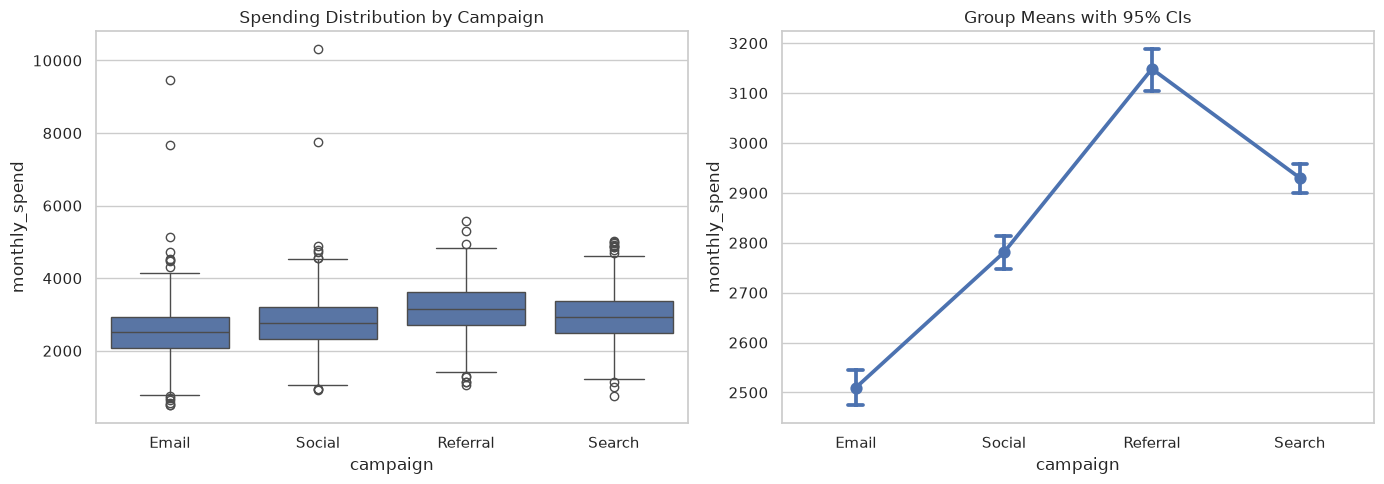

In [29]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.boxplot(data=data,x="campaign",y="monthly_spend",ax=axes[0])
axes[0].set_title("Spending Distribution by Campaign")
sns.pointplot(data=data,x="campaign",y="monthly_spend",
              errorbar=("ci",95),capsize=.1,ax=axes[1])
axes[1].set_title("Group Means with 95% CIs")
plt.tight_layout()
plt.show()

Interpretation: Boxplots show medians, quartiles, whiskers and potential outliers. Point plots show means and uncertainty intervals. Overlap/non-overlap of these intervals is not a substitute for ANOVA or post-hoc tests.